In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Make plots look consistent
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

csv_path = Path("data/lots_of_repos.csv")

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 1238
Columns: 9


,description,forks,language,name,owner,size,stars,updated_at,url
0,Docker Image of Ansible for executing ansible-...,83,Shell,docker-ansible-playbook,walokra,8,99,2026-01-30T12:17:30Z,https://github.com/walokra/docker-ansible-play...
1,This is still a work in progress,71,JavaScript,glamorous-website,kentcdodds,1478,99,2025-02-06T00:42:54Z,https://github.com/kentcdodds/glamorous-website
2,Microservices reference app showcasing a range...,45,JavaScript,smilr,benc-uk,47417,99,2026-07-04T20:00:08Z,https://github.com/benc-uk/smilr
3,Rendering API for nivo dataviz React/d3 compon...,14,JavaScript,nivo-api,plouc,71,99,2024-11-18T03:35:22Z,https://github.com/plouc/nivo-api
4,后端ssm + 前端bootstrap + maven搭建的高并发秒杀系统,46,Java,SpikeSystem,jeff-leo,34,99,2026-03-16T10:32:31Z,https://github.com/jeff-leo/SpikeSystem


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("Total rows:", len(df))

if "url" in df.columns:
    print("Unique URLs:", df["url"].nunique())
    print("Duplicate URLs:", df["url"].duplicated().sum())

    duplicates = df[df["url"].duplicated(keep=False)]
    display(duplicates.head(10))

Column names:
['description', 'forks', 'language', 'name', 'owner', 'size', 'stars', 'updated_at', 'url']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1238 entries, 0 to 1237
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   description  1135 non-null   str  
 1   forks        1238 non-null   int64
 2   language     1126 non-null   str  
 3   name         1238 non-null   str  
 4   owner        1238 non-null   str  
 5   size         1238 non-null   int64
 6   stars        1238 non-null   int64
 7   updated_at   1238 non-null   str  
 8   url          1238 non-null   str  
dtypes: int64(3), str(6)
memory usage: 87.2 KB
Total rows: 1238
Unique URLs: 1238
Duplicate URLs: 0


,description,forks,language,name,owner,size,stars,updated_at,url


In [4]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing.sort_values("missing_percent", ascending=False)


,missing_count,missing_percent
language,112,9.05
description,103,8.32
forks,0,0.00
name,0,0.00
owner,0,0.00
size,0,0.00
stars,0,0.00
updated_at,0,0.00
url,0,0.00


stars    int64
forks    int64
size     int64
dtype: object
           stars      forks        size
count    1238.00    1238.00     1238.00
mean    16512.57    2621.99    58290.77
std     60405.10   10481.03   423255.99
min         0.00       0.00        0.00
25%        44.00       7.00      148.25
50%       213.00      36.50     1078.00
75%       823.75     130.75     6827.75
max    554415.00  107908.00  9629193.00


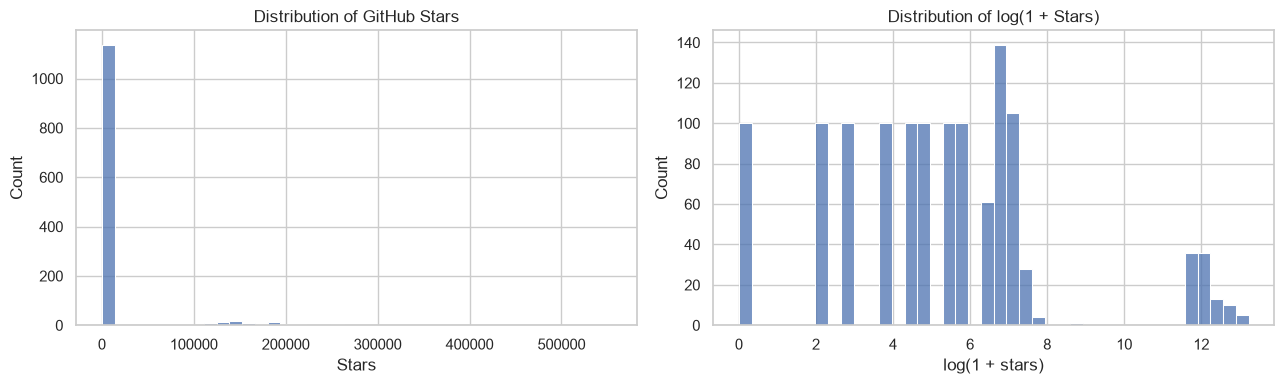

stars
Under 100    500
100–999      500
1,000+       238
Name: count, dtype: int64


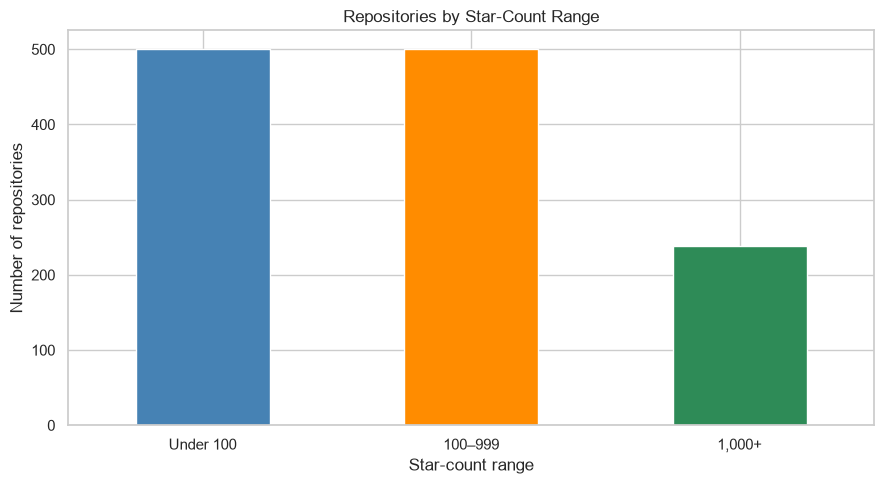

In [13]:
numeric_cols = ["stars", "forks", "size"]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_cols].dtypes)
print(df[numeric_cols].describe().round(2))

star_data = df["stars"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(star_data, bins=40, ax=axes[0])
axes[0].set_title("Distribution of GitHub Stars")
axes[0].set_xlabel("Stars")

sns.histplot(np.log1p(star_data), bins=40, ax=axes[1])
axes[1].set_title("Distribution of log(1 + Stars)")
axes[1].set_xlabel("log(1 + stars)")

plt.tight_layout()
plt.show()

star_bins = pd.cut(
    df["stars"],
    bins=[-1, 99, 999, np.inf],
    labels=["Under 100", "100–999", "1,000+"]
)

print(star_bins.value_counts(sort=False))

star_bins.value_counts(sort=False).plot(
    kind="bar",
    color=["steelblue", "darkorange", "seagreen"]
)

plt.title("Repositories by Star-Count Range")
plt.xlabel("Star-count range")
plt.ylabel("Number of repositories")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Median star threshold: 213.0

Popularity class counts:
popularity
high    638
low     600
Name: count, dtype: int64

Popularity class proportions:
popularity
high    51.53%
low     48.47%
Name: proportion, dtype: str


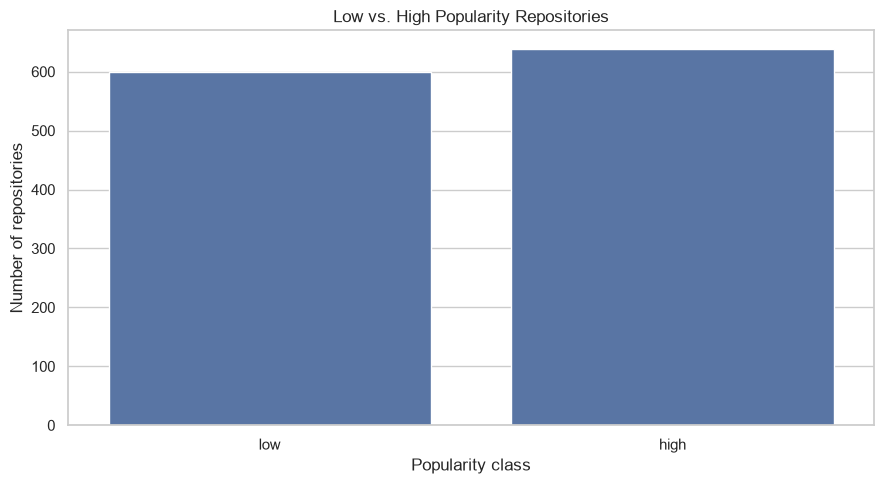

In [9]:
model_df = df.dropna(subset=["stars"]).copy()

star_threshold = model_df["stars"].median()

model_df["popularity"] = np.where(
    model_df["stars"] >= star_threshold,
    "high",
    "low"
)

print("Median star threshold:", star_threshold)
print("\nPopularity class counts:")
print(model_df["popularity"].value_counts())

print("\nPopularity class proportions:")
print(
    model_df["popularity"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str) + "%"
)

sns.countplot(
    data=model_df,
    x="popularity",
    order=["low", "high"]
)

plt.title("Low vs. High Popularity Repositories")
plt.xlabel("Popularity class")
plt.ylabel("Number of repositories")
plt.tight_layout()
plt.show()

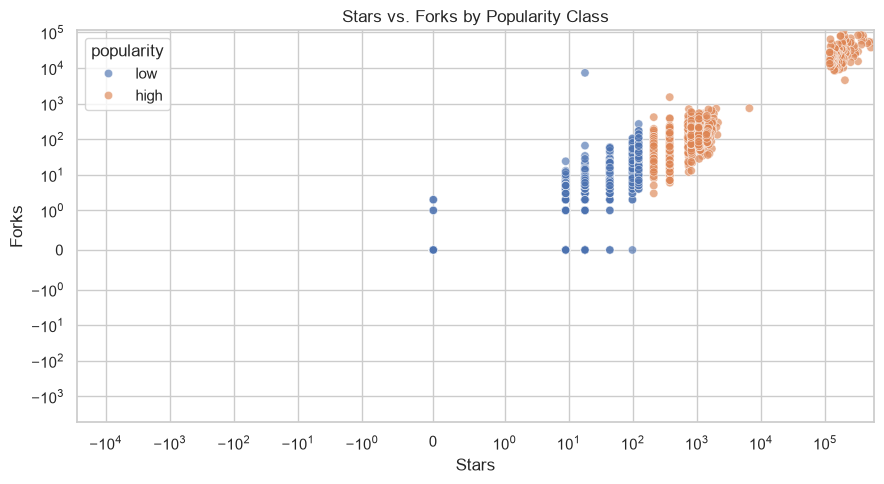

Spearman correlation between stars and forks: 0.9001749298233829


In [10]:
plot_df = model_df.dropna(subset=["stars", "forks"]).copy()

sns.scatterplot(
    data=plot_df,
    x="stars",
    y="forks",
    hue="popularity",
    alpha=0.65
)

plt.xscale("symlog", linthresh=1)
plt.yscale("symlog", linthresh=1)
plt.title("Stars vs. Forks by Popularity Class")
plt.xlabel("Stars")
plt.ylabel("Forks")
plt.tight_layout()
plt.show()

print(
    "Spearman correlation between stars and forks:",
    plot_df[["stars", "forks"]].corr(method="spearman").iloc[0, 1]
)

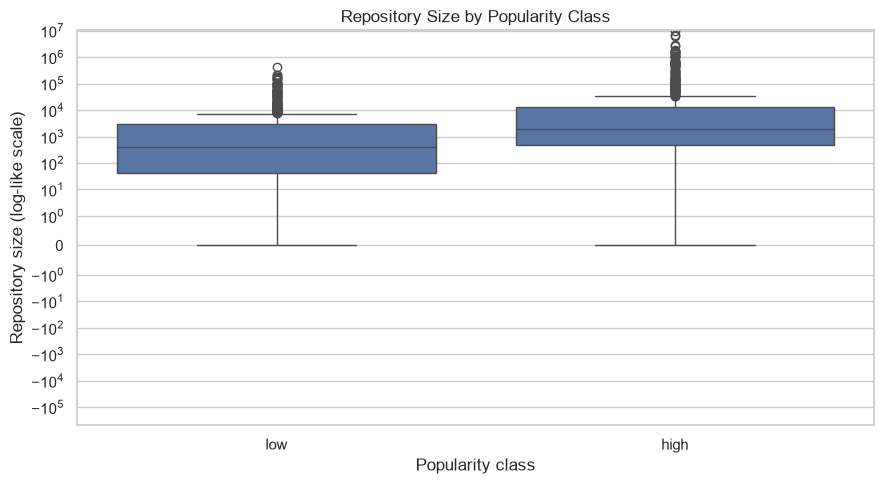

In [11]:
sns.boxplot(
    data=model_df.dropna(subset=["size"]),
    x="popularity",
    y="size",
    order=["low", "high"]
)

plt.yscale("symlog", linthresh=1)
plt.title("Repository Size by Popularity Class")
plt.xlabel("Popularity class")
plt.ylabel("Repository size (log-like scale)")
plt.tight_layout()
plt.show()

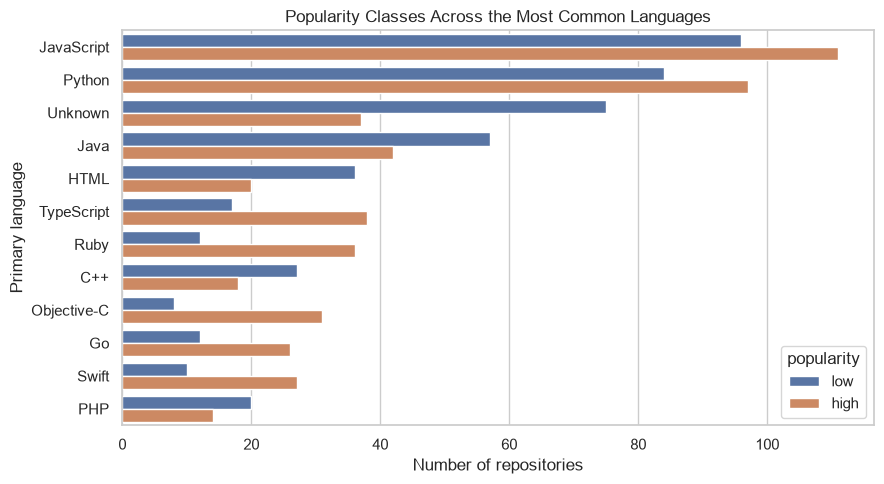

In [12]:

language_df = model_df.copy()
language_df["language"] = language_df["language"].fillna("Unknown")

top_languages = (
    language_df["language"]
    .value_counts()
    .head(12)
    .index
)

language_df = language_df[
    language_df["language"].isin(top_languages)
]

sns.countplot(
    data=language_df,
    y="language",
    hue="popularity",
    order=top_languages
)

plt.title("Popularity Classes Across the Most Common Languages")
plt.xlabel("Number of repositories")
plt.ylabel("Primary language")
plt.tight_layout()
plt.show()

In [14]:
# Convert updated_at into proper datetime values
df["updated_at"] = pd.to_datetime(
    df["updated_at"],
    errors="coerce",
    utc=True
)

# Use a consistent reference time for this analysis
analysis_time = pd.Timestamp.now(tz="UTC")

# Calculate the number of days since the last update
df["days_since_update"] = (
    analysis_time - df["updated_at"]
).dt.total_seconds() / 86400

# Inspect the results
print("Missing or invalid dates:", df["updated_at"].isna().sum())
print("\nDays since update:")
print(df["days_since_update"].describe().round(2))

print(
    "\nRepositories with future update dates:",
    (df["days_since_update"] < 0).sum()
)

Missing or invalid dates: 0

Days since update:
count    1238.00
mean      509.90
std       881.45
min         0.03
25%        96.76
50%       153.75
75%       430.61
max      3392.05
Name: days_since_update, dtype: float64

Repositories with future update dates: 0


In [15]:
# Keep rows with valid numeric predictors and a target
model_df = df.dropna(
    subset=[
        "stars",
        "forks",
        "size",
        "days_since_update"
    ]
).copy()

# Remove impossible negative values
nonnegative_cols = [
    "stars",
    "forks",
    "size",
    "days_since_update"
]

model_df = model_df[
    (model_df[nonnegative_cols] >= 0).all(axis=1)
].copy()

# Create the popularity target using the median from our initial analysis
star_threshold = model_df["stars"].median()

model_df["popularity"] = np.where(
    model_df["stars"] >= star_threshold,
    "high",
    "low"
)

# Fill missing language values with an explicit category
model_df["language"] = (
    model_df["language"]
    .fillna("Unknown")
    .astype(str)
)

print("Rows available for modeling:", len(model_df))
print("Star threshold:", star_threshold)
print("\nTarget distribution:")
print(model_df["popularity"].value_counts())

print("\nPredictor preview:")
display(
    model_df[
        [
            "forks",
            "size",
            "days_since_update",
            "language",
            "stars",
            "popularity"
        ]
    ].head()
)

Rows available for modeling: 1238
Star threshold: 213.0

Target distribution:
popularity
high    638
low     600
Name: count, dtype: int64

Predictor preview:


,forks,size,days_since_update,language,stars,popularity
0,83,8,261.800577,Shell,99,low
1,71,1478,620.282938,JavaScript,99,low
2,45,47417,106.479304,JavaScript,99,low
3,14,71,700.163169,JavaScript,99,low
4,46,34,216.873482,Java,99,low


In [16]:
numeric_features = [
    "forks",
    "size",
    "days_since_update"
]

X_numeric = model_df[numeric_features].copy()

X_numeric = np.log1p(X_numeric)

display(X_numeric.describe().round(3))

,forks,size,days_since_update
count,1238.000,1238.000,1238.000
mean,3.747,6.920,5.087
std,2.535,2.982,1.845
min,0.000,0.000,0.027
25%,2.079,5.006,4.582
50%,3.624,6.984,5.042
75%,4.881,8.829,6.068
max,11.589,16.080,8.129


In [17]:
X_language = pd.get_dummies(
    model_df["language"],
    prefix="language",
    dtype=float
)

print("Number of language categories:", model_df["language"].nunique())
print("Number of encoded columns:", X_language.shape[1])

display(X_language.head())

Number of language categories: 72
Number of encoded columns: 72


,language_1C Enterprise,language_ANTLR,language_API Blueprint,language_ActionScript,language_Arduino,language_Batchfile,language_C,language_C#,language_C++,language_CMake,...,language_Thrift,language_TypeScript,language_Unknown,language_VBA,language_Vim Script,language_Vim script,language_VimL,language_Vue,language_XSLT,language_YASnippet
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
X = pd.concat(
    [
        X_numeric.reset_index(drop=True),
        X_language.reset_index(drop=True)
    ],
    axis=1
)

y = model_df["popularity"].reset_index(drop=True)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget counts:")
print(y.value_counts())

print("\nAny missing feature values?", X.isna().any().any())
print("Any infinite feature values?", np.isinf(X.to_numpy()).any())

display(X.head())

Feature matrix shape: (1238, 75)
Target shape: (1238,)

Target counts:
popularity
high    638
low     600
Name: count, dtype: int64

Any missing feature values? False
Any infinite feature values? False


,forks,size,days_since_update,language_1C Enterprise,language_ANTLR,language_API Blueprint,language_ActionScript,language_Arduino,language_Batchfile,language_C,...,language_Thrift,language_TypeScript,language_Unknown,language_VBA,language_Vim Script,language_Vim script,language_VimL,language_Vue,language_XSLT,language_YASnippet
0,4.430817,2.197225,5.571395,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,4.276666,7.299121,6.431787,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.828641,10.766757,4.677298,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2.708050,4.276666,6.552741,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,3.850148,3.555348,5.383915,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training rows: 928
Testing rows: 310

Training class proportions:
popularity
high    0.515
low     0.485
Name: proportion, dtype: float64

Testing class proportions:
popularity
high    0.516
low     0.484
Name: proportion, dtype: float64


In [20]:
from sklearn.naive_bayes import GaussianNB

# Initialize and train the classifier
gnb = GaussianNB()

gnb.fit(X_train, y_train)

# Predict popularity on unseen test data
y_pred = gnb.predict(X_test)

print("Model trained successfully.")
print("Number of test predictions:", len(y_pred))
print("\nFirst 10 predictions:")
print(y_pred[:10])

Model trained successfully.
Number of test predictions: 310

First 10 predictions:
['high' 'high' 'high' 'high' 'high' 'high' 'high' 'high' 'high' 'high']


Test accuracy: 0.529 (52.9%)

Classification report:
              precision    recall  f1-score   support

        high       0.52      0.96      0.68       160
         low       0.61      0.07      0.13       150

    accuracy                           0.53       310
   macro avg       0.57      0.51      0.40       310
weighted avg       0.57      0.53      0.41       310



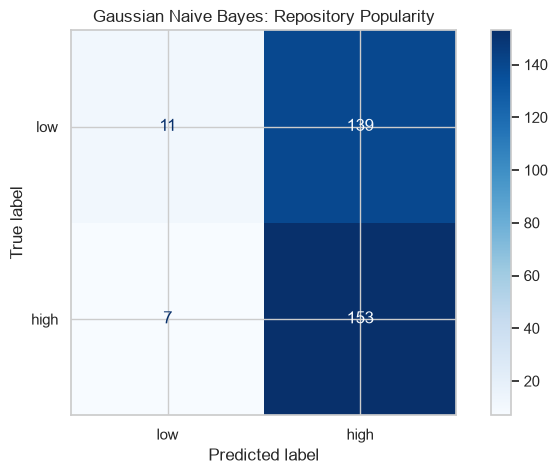

stars            forks             size             \
           median      mean median     mean  median       mean   
popularity                                                       
high        821.0  31995.55  122.5  5061.62  1903.0  105099.48   
low          31.0     49.00    7.0    27.85   389.5    8517.52   

           days_since_update          
                      median    mean  
popularity                            
high                  102.24  116.14  
low                   434.96  928.60

In [22]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.3f} ({accuracy:.1%})")

# Show precision, recall, F1-score, and class support
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["low", "high"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["low", "high"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Gaussian Naive Bayes: Repository Popularity")
plt.show()

summary = (
    model_df
    .groupby("popularity")[["stars", "forks", "size", "days_since_update"]]
    .agg(["median", "mean"])
    .round(2)
)

display(summary)